# Autoencoder

Một bảng đo có bốn cảm biến cùng thay đổi theo mức hoạt động của thiết bị. Có cần lưu đủ bốn số, hay có thể nén chúng thành một số rồi dựng lại? Khi một cảm biến lệch khỏi các cảm biến còn lại, sai số dựng lại có thể báo một mẫu cần kiểm. Autoencoder học phép nén và tái tạo, nhưng “tái tạo kém” chỉ là tín hiệu thống kê, chưa phải kết luận thiết bị hỏng.

> **Mục tiêu sau bài này**
>
> - Giải thích encoder, latent code, decoder và reconstruction loss.
> - So một autoencoder tuyến tính nhỏ với phép chiếu PCA.
> - Dùng dữ liệu bình thường để chọn ngưỡng sai số tái tạo trên validation.
> - Phân biệt tái tạo, khử nhiễu và phát hiện bất thường; đọc các giới hạn của từng mục tiêu.

## Nén là một ràng buộc thông tin

Encoder $f_\theta$ đổi $\mathbf{x}$ thành code $\mathbf{z}$ ít chiều hơn; decoder $g_\phi$ đổi code thành $\hat{\mathbf{x}}$. Training cực tiểu sai khác giữa input và reconstruction, trung bình trên batch $B$ mẫu, mỗi mẫu $d$ feature:

$$\mathbf{z}=f_\theta(\mathbf{x}),\qquad
\hat{\mathbf{x}}=g_\phi(\mathbf{z}),\qquad
J=\frac{1}{Bd}\sum_{i,j}(\hat x_{i,j}-x_{i,j})^2.$$

Code ít chiều, còn gọi là biểu diễn ẩn (latent), tạo nút thắt (bottleneck): model không đủ chỗ chép mọi chi tiết nên phải giữ cấu trúc chung. Ảnh chữ số $28 \times 28$ nén về 32 chiều là bớt từ 784 xuống 32 số, khoảng 24.5 lần. Với ảnh, lỗi MSE cộng nút thắt hẹp thường làm ảnh tái tạo mờ: chi tiết nào không giữ được, model trả trung bình của chúng. Nếu latent rộng bằng input hoặc encoder/decoder quá mạnh, model có thể học phép chép lại và tái tạo tốt cả mẫu lạ; vì vậy loss reconstruction nhỏ không tự chứng minh code hữu ích. Nén tọa độ trong lập trình thi đấu giữ nguyên mọi quan hệ thứ tự mà thuật toán cần; autoencoder thì bỏ thông tin theo loss, nên có thể bỏ luôn thứ mà một nhiệm vụ khác cần.



Hai nửa của model có thể chạy ở hai nơi. Khi nén để truyền, thiết bị chạy encoder và chỉ gửi $\mathbf z$; nơi nhận giữ decoder để dựng $\hat{\mathbf x}$. Khi phát hiện bất thường, hai nửa chạy liền nhau, vì score phải so $\hat{\mathbf x}$ với chính $\mathbf x$.

**Hỏi nhanh.** Một trạm có 100 cảm biến, đường truyền chỉ đủ gửi 8 số mỗi giây, còn máy chủ cần dựng lại đủ 100 số. Dùng autoencoder $100 \to 8 \to 100$ thế nào?

- A. Trạm chạy cả hai nửa rồi gửi $\hat{\mathbf x}$ đủ 100 số
- B. Trạm chạy encoder và gửi $\mathbf z$, máy chủ chạy decoder
- C. Trạm gửi 8 cảm biến đầu, máy chủ chạy encoder
- D. Trạm chạy decoder và gửi 8 số, máy chủ chạy encoder

<details><summary>Đáp án</summary>

B. Trạm chạy encoder và gửi $\mathbf z$, máy chủ chạy decoder

Chỉ $\mathbf z$ gồm 8 số mới vừa đường truyền, và decoder phải đặt ở nơi cần 100 số. Gửi $\hat{\mathbf x}$ vẫn tốn 100 số. Gửi 8 cảm biến đầu là bỏ hẳn 92 cột, thay vì nén thông tin của cả 100. Đảo vai thì sai cả shape, vì decoder nhận 8 số chứ không nhận 100.

</details>

## Dữ liệu có một cấu trúc biết trước

Ta sinh bốn cảm biến cùng phụ thuộc một số $t$: $[t,2t,-t,0.5t]$ cộng nhiễu nhỏ. Cấu trúc sạch thật sự chỉ có một bậc tự do, nên nén về một chiều có lý do. Train, validation và test được sinh riêng; mean/std chỉ lấy train. Các vector không bị ép vào 0–1, vì vậy decoder cuối để linear, không dùng sigmoid.

In [ ]:
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(43)
g = torch.Generator().manual_seed(43)
direction = torch.tensor([1., 2., -1., .5])

def make_normal(n):
    t = torch.randn(n, 1, generator=g)
    clean = t * direction
    noisy = clean + .03 * torch.randn(n, 4, generator=g)
    return clean, noisy

clean_train, raw_train = make_normal(128)
_, raw_valid = make_normal(48)
_, raw_normal_test = make_normal(32)
_, raw_anomaly_test = make_normal(16)
raw_anomaly_test[:, 1] += 1.5
mean = raw_train.mean(dim=0)
scale = raw_train.std(dim=0, unbiased=False).clamp_min(1e-6)
train = (raw_train - mean) / scale
valid = (raw_valid - mean) / scale
test = (torch.cat([raw_normal_test, raw_anomaly_test]) - mean) / scale
test_labels = torch.cat([torch.zeros(32), torch.ones(16)]).long()
print(tuple(train.shape), tuple(valid.shape), tuple(test.shape))

(128, 4) (48, 4) (48, 4)


Các mẫu anomaly được tạo bằng cách lệch riêng cảm biến thứ hai. Đây là định nghĩa bất thường trong bộ mô phỏng này. Trong dữ liệu thật, nhãn hoặc tri thức chuyên môn phải quyết định điều gì đáng báo; một giá trị xa trung bình vẫn có thể là hoạt động hợp lệ. Chuẩn hóa quan trọng vì MSE cộng theo feature: cảm biến có đơn vị lớn sẽ chi phối nếu không chọn thang đo hợp lý.

**Hỏi nhanh.** Target của autoencoder đã chuẩn hóa z-score, nên có giá trị âm và giá trị lớn hơn 1. Vì sao decoder để lớp cuối linear lại hợp hơn sigmoid?

- A. Sigmoid không cho gradient khi input của nó âm
- B. MSE chỉ tính được khi decoder không có bias
- C. Linear tự bảo đảm phát hiện được mọi bất thường
- D. Sigmoid chỉ cho ra số trong $(0, 1)$, không phủ được miền của target

<details><summary>Đáp án</summary>

D. Sigmoid chỉ cho ra số trong $(0, 1)$, không phủ được miền của target

Activation cuối phải phủ được miền của target. Target z-score có số âm và số lớn hơn 1, mà sigmoid không bao giờ cho ra được, nên lỗi tái tạo có một mức sàn không giảm nổi. Sigmoid vẫn có gradient khi input âm, chỉ nhỏ dần khi rất âm. Bias không liên quan tới việc tính MSE. Activation cuối cũng không quyết định khả năng phát hiện bất thường.

</details>

## Ví dụ tính tay: nén về đường chung

Với hai cảm biến sạch trên đường $x_2=x_1$, chọn encoder $z=(x_1+x_2)/2$ và decoder $(z,z)$. Mẫu $[1,1]$ tái tạo đúng. Mẫu $[0.9,0.1]$ cho $z=0.5$, tái tạo $[0.5,0.5]$, MSE $((0.4)^2+(-0.4)^2)/2=0.16$. Phép chiếu bỏ phần lệch khỏi cấu trúc chung.



Nếu một mẫu lạ vẫn nằm trên đường ấy, ví dụ $[100,100]$, công thức trên tái tạo đúng. Một anomaly về **độ lớn dọc cấu trúc** có thể không được reconstruction error phát hiện. Đây là giới hạn cần hiểu trước khi gọi model là bộ phát hiện bất thường.

**Hỏi nhanh.** Vẫn dùng encoder $z = (x_1 + x_2)/2$ và decoder $(z, z)$. Xếp ba mẫu A $= [5, 5]$, B $= [1.2, 0.8]$, C $= [0, 0.6]$ theo MSE tái tạo, từ lớn đến nhỏ.

- A. A > B > C
- B. A > C > B
- C. C > B > A
- D. B > C > A

<details><summary>Đáp án</summary>

C. C > B > A

A nằm đúng trên đường $x_2 = x_1$, nên lỗi bằng 0, dù xa gốc nhất. B được tái tạo thành $[1, 1]$, lỗi là $(0.2^2 + 0.2^2)/2 = 0.04$. C được tái tạo thành $[0.3, 0.3]$, lỗi là $0.09$. Tổng quát, lỗi bằng $(x_1 - x_2)^2/4$: score đo độ lệch khỏi đường, không đo độ lớn. Xếp A đầu tiên là nhầm score với khoảng cách tới gốc.

</details>

## Tự cài baseline PCA trước

Với dữ liệu đã trừ mean, PCA một chiều chính là một autoencoder tuyến tính viết sẵn: encoder $z=\mathbf e^\top\mathbf x$ chiếu lên hướng chính $\mathbf e$ (vector đơn vị), decoder $\hat{\mathbf x}=z\,\mathbf e$ chiếu ngược. Theo định lý Eckart–Young, trong mọi cách nén tuyến tính về $k$ chiều rồi dựng lại, $k$ thành phần chính đầu tiên cho MSE trên train nhỏ nhất. Vì vậy PCA vừa là baseline vừa là cận dưới cho autoencoder tuyến tính: mạng tối ưu tốt sẽ học cùng phép chiếu, dù latent của nó có thể bằng tọa độ PCA nhân một hệ số khác 0.

In [ ]:
train_np = train.numpy()
_, singular_values, vt = np.linalg.svd(train_np, full_matrices=False)
axis = vt[0]
latent_np = train_np @ axis
reconstruction_np = latent_np[:, None] * axis[None, :]
print('PCA latent shape:', latent_np.shape)
print('PCA train MSE:', round(float(np.mean((reconstruction_np - train_np) ** 2)), 6))
print('variance fraction:', round(float(singular_values[0] ** 2 /
                                       np.sum(singular_values ** 2)), 6))

PCA latent shape: (128,)
PCA train MSE: 0.001006
variance fraction: 0.998994


Hai số ăn khớp nhau. Sau chuẩn hóa, mỗi cột có phương sai 1, tổng phương sai là 4; MSE trung bình trên bốn cột đúng bằng phần phương sai bị bỏ: $1-0.998994=0.001006$. Tỉ lệ giữ lại cao phù hợp thiết kế một biến $t$ điều khiển bốn cảm biến. Nhưng phương sai lớn chưa chắc mang thông tin cho nhãn: nhãn có thể phụ thuộc đúng một hướng ít phương sai mà phép nén đã bỏ. Baseline này kiểm mục tiêu reconstruction, không thay cho đánh giá của nhiệm vụ dùng code về sau.

**Hỏi nhanh.** Hai linear autoencoder $4 \to 1 \to 4$ không bias cho cùng một reconstruction trên mọi mẫu, nhưng latent của model B luôn gấp đôi latent của model A. Điều này có mâu thuẫn không?

- A. Không, vì decoder của B chia đôi để bù lại
- B. Có, vì latent tối ưu phải trùng tọa độ PCA
- C. Có, vì latent gấp đôi thì output cũng gấp đôi
- D. Có, vì chỉ đổi seed mới làm latent khác đi

<details><summary>Đáp án</summary>

A. Không, vì decoder của B chia đôi để bù lại

Output là $W_dW_e\mathbf x$. Nhân $W_e$ với 2 và chia $W_d$ cho 2 thì tích không đổi. Vì vậy reconstruction không xác định duy nhất tọa độ latent, kể cả ở nghiệm tối ưu; tọa độ PCA chỉ là một cách chọn thang. Latent gấp đôi chỉ làm output gấp đôi khi decoder giữ nguyên. Seed cũng không phải nguồn duy nhất làm latent khác nhau.

</details>

**Hỏi nhanh.** Dữ liệu 5 cột đã chuẩn hóa, mỗi cột có phương sai 1. PCA giữ 2 thành phần, giải thích được 90% phương sai. MSE tái tạo trên train, lấy trung bình theo mẫu và theo cột, bằng bao nhiêu?

- A. 0.02
- B. 0.1
- C. 0.5
- D. 0.9

<details><summary>Đáp án</summary>

B. 0.1

Tổng phương sai là 5, phần bị bỏ là $10\%\cdot 5 = 0.5$. Chia cho 5 cột được $0.1$, đúng bằng $1 - 0.9$ như ví dụ của bài. 0.5 là tổng bình phương lỗi của mỗi mẫu, chưa chia cho số cột. 0.02 là chia cho 5 hai lần. 0.9 là phần được giữ, không phải phần mất.

</details>

## Học encoder/decoder bằng PyTorch

Ta dùng mạng linear $4\to1\to4$ không bias, vì dữ liệu đã center theo train và cấu trúc thật chỉ có một bậc tự do. Muốn học cấu trúc cong, autoencoder cần tầng ẩn có activation như ReLU; xếp thêm tầng linear mà không có activation chỉ tạo ra một phép tuyến tính khác, không vượt được PCA. Với dữ liệu thẳng như ở đây, mạng nhỏ nhất là đủ để kiểm pipeline.

In [ ]:
class LinearAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Linear(4, 1, bias=False)
        self.decoder = nn.Linear(1, 4, bias=False)

    def forward(self, x):
        return self.decoder(self.encoder(x))

autoencoder = LinearAutoencoder()
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=.03)
initial_loss = (autoencoder(train) - train).square().mean().item()
for _ in range(300):
    autoencoder.train()
    optimizer.zero_grad(set_to_none=True)
    reconstructed = autoencoder(train)
    assert reconstructed.shape == train.shape
    loss = (reconstructed - train).square().mean()
    loss.backward()
    optimizer.step()
autoencoder.eval()
with torch.no_grad():
    final_loss = (autoencoder(train) - train).square().mean().item()
    valid_loss = (autoencoder(valid) - valid).square().mean().item()
    codes = autoencoder.encoder(valid)
print('train MSE:', round(initial_loss, 6), '->', round(final_loss, 6))
print('validation MSE:', round(valid_loss, 6))
print('latent:', tuple(codes.shape))

train MSE: 0.22791 -> 0.001038
validation MSE: 0.00094
latent: (48, 1)


Train MSE giảm từ 0.22791 xuống 0.001038, chỉ cao hơn cận dưới PCA 0.001006 khoảng 3%: 300 bước Adam đã tới rất gần phép chiếu tối ưu. Validation 0.00094 thấp hơn train một chút; với 48 mẫu, chênh lệch cỡ này là dao động ngẫu nhiên của nhiễu, không phải dấu hiệu rò rỉ. `codes` có shape `(48,1)`, một số mỗi mẫu; dấu và thang của nó có thể đổi theo seed, nên khi dùng code làm feature cho clustering hay classifier, phải đánh giá lại trên split của nhiệm vụ ấy.



**Hỏi nhanh.** Sau khi train lâu hơn, một bạn báo linear autoencoder $4 \to 1 \to 4$ không bias đạt MSE 0.0009 trên train, trong khi trên đúng tập train ấy, PCA một chiều cho 0.001006. Nên nghĩ gì trước tiên?

- A. Hợp lý, vì mạng có 8 weight nên khớp tốt hơn PCA
- B. Hợp lý, vì Adam tìm được nghiệm mà SVD bỏ sót
- C. Đáng ngờ, vì PCA là cận dưới, nên phải kiểm lại phép đo
- D. Đáng ngờ, vì linear AE luôn có MSE gấp đôi PCA

<details><summary>Đáp án</summary>

C. Đáng ngờ, vì PCA là cận dưới, nên phải kiểm lại phép đo

Theo định lý Eckart–Young, không phép nén rồi dựng tuyến tính một chiều nào có MSE trên train nhỏ hơn PCA, dù có bao nhiêu weight hay dùng optimizer nào. Một con số thấp hơn cận dưới là dấu hiệu đo sai: tính trên tập khác, chuẩn hóa khác, hay chia cho mẫu số khác. Mạng có thể chạm cận dưới nhưng không vượt qua được. Còn “gấp đôi” thì không có cơ sở, vì bài vừa đo được 0.001038 so với 0.001006.

</details>

## Từ reconstruction error tới ngưỡng báo

Tính lỗi cho **từng mẫu**, trung bình theo feature, không gộp mất chiều batch. Chọn threshold trên validation bình thường, chẳng hạn phân vị 95%; đây là heuristic đặt mức báo tương đối, không bảo đảm false-positive chính xác 5% trên mọi test. Validation nhỏ làm ngưỡng dao động; dữ liệu lệch phân phối có thể tăng số báo sai. Bài toán này gọi là phát hiện bất thường (anomaly detection): hợp khi gần như chỉ có dữ liệu bình thường, còn lỗi thì hiếm và mỗi lần một kiểu, như máy hỏng, vết xước trên dây chuyền hay giao dịch gian lận. Cách cổ điển hơn là khớp một phân phối chuẩn cho từng đặc trưng rồi báo khi $p(\mathbf x) < \varepsilon$; $\varepsilon$ càng lớn thì càng ít bỏ sót nhưng càng báo nhầm nhiều.

In [ ]:
def reconstruction_error(model, x):
    model.eval()
    with torch.no_grad():
        return (model(x) - x).square().mean(dim=1)

valid_error = reconstruction_error(autoencoder, valid)
threshold = torch.quantile(valid_error, .95).item()
test_error = reconstruction_error(autoencoder, test)
flag = test_error > threshold
true_positive = (flag & test_labels.eq(1)).sum().item()
false_positive = (flag & test_labels.eq(0)).sum().item()
false_negative = ((~flag) & test_labels.eq(1)).sum().item()
print('threshold:', round(threshold, 6))
print('normal/anomaly median error:', round(test_error[:32].median().item(), 6),
      round(test_error[32:].median().item(), 6))
print('TP FP FN:', true_positive, false_positive, false_negative)

threshold: 0.002907
normal/anomaly median error: 0.000808 0.106747
TP FP FN: 16 2 0


Hai median cách nhau hơn trăm lần (0.000808 so với 0.106747), nên score tách hai nhóm rất rõ. Ngưỡng bắt đủ 16 mẫu bất thường (FN = 0) và báo nhầm 2 trong 32 mẫu bình thường, tức 6.25%, gần mức 5% mà phân vị 95% nhắm tới; với 32 mẫu, mỗi mẫu đã là hơn 3 điểm phần trăm. Nhãn test chỉ dùng để chấm, không dùng chọn ngưỡng. Nếu có validation chứa anomaly đã gắn nhãn, chọn ngưỡng tối đa F1 trên đó cũng hợp lệ, nhưng khi ấy bài toán đã dùng nhãn, không còn là phát hiện bất thường không giám sát.



Trên thang log, nhóm bất thường nằm cách ngưỡng hơn một bậc độ lớn, còn ngưỡng nằm sát đuôi của nhóm bình thường. Vì vậy dời ngưỡng trong vùng này chủ yếu đổi số FP, hầu như không đổi TP.

**Hỏi nhanh.** Bình phương sai số reconstruction có shape `(B, 4)`. Muốn mỗi mẫu có một MSE anomaly score, phải gộp theo chiều nào?

- A. Lấy mean theo `dim=0`, giữ lại 4 số
- B. Lấy sum theo `dim=0`, rồi chia cho $B$
- C. Lấy mean trên mọi chiều, chỉ còn một số
- D. Lấy mean theo `dim=1`, giữ lại $B$ số

<details><summary>Đáp án</summary>

D. Lấy mean theo `dim=1`, giữ lại $B$ số

Score của một mẫu gộp 4 feature của chính hàng ấy, nên lấy mean theo `dim=1` và giữ lại $B$ số để so với ngưỡng. Gộp theo `dim=0`, dù là mean hay sum chia cho $B$, cho ra lỗi trung bình của từng feature trên cả batch. Mean trên mọi chiều là loss của batch, cần khi train nhưng không xếp hạng được từng mẫu.

</details>

**Hỏi nhanh.** Đổi ngưỡng từ phân vị 95% lên phân vị 99% của cùng một tập validation, giữ nguyên model. Trên cùng tập test, câu nào về TP và FP luôn đúng?

- A. TP không giảm, FP không tăng
- B. TP không giảm, FP không giảm
- C. TP không tăng, FP không giảm
- D. TP không tăng, FP không tăng

<details><summary>Đáp án</summary>

D. TP không tăng, FP không tăng

Ngưỡng cao hơn thì tập mẫu bị đánh dấu chỉ có thể co lại, nên cả TP lẫn FP đều không tăng: báo nhầm ít hơn, đổi lại có thể bỏ sót thêm bất thường. Ba phương án còn lại đều khẳng định có ít nhất một số không giảm, điều chỉ đúng khi không có mẫu nào nằm giữa hai ngưỡng. Ở bài này, nhóm bất thường nằm xa ngưỡng, nên nâng ngưỡng chủ yếu là bớt FP.

</details>

## Denoising thay target của việc học

Autoencoder thông thường nhận $\mathbf x$ và tái tạo $\mathbf x$; denoising autoencoder nhận bản bị nhiễu $\tilde{\mathbf x}$ nhưng target là $\mathbf x$ sạch. Nếu target cũng nhiễu, model được thưởng khi giữ nhiễu. Lọc tiếng gõ phím, tiếng quạt mà giữ giọng nói trong ứng dụng họp trực tuyến là cùng bài toán trên âm thanh. Khi có cặp noisy/clean hoặc cơ chế mô phỏng nhiễu hợp lệ, ta cực tiểu $\lVert g(f(\tilde{\mathbf x}))-\mathbf x\rVert^2$.

Mô phỏng có sẵn `clean_train`, nên mỗi step ta tạo một bản nhiễu mới với độ lệch chuẩn 0.15 trên thang đã chuẩn hóa; model không thể học thuộc một bản nhiễu cố định. Đánh giá trên 24 cặp clean/noisy mới, dùng lại mean/std của train, và so với cách đơn giản nhất là giữ nguyên noisy input:

In [ ]:
torch.manual_seed(47)
denoiser = LinearAutoencoder()
denoise_optimizer = torch.optim.Adam(denoiser.parameters(), lr=.03)
clean_scaled = (clean_train - mean) / scale
noise_generator = torch.Generator().manual_seed(47)
for _ in range(200):
    corrupted = clean_scaled + .15 * torch.randn(clean_scaled.shape, generator=noise_generator)
    denoise_optimizer.zero_grad(set_to_none=True)
    loss = (denoiser(corrupted) - clean_scaled).square().mean()
    loss.backward()
    denoise_optimizer.step()
clean_eval, _ = make_normal(24)
clean_eval = (clean_eval - mean) / scale
noisy_eval = clean_eval + .15 * torch.randn(clean_eval.shape, generator=noise_generator)
denoiser.eval()
with torch.no_grad():
    baseline = (noisy_eval - clean_eval).square().mean().item()
    denoised = (denoiser(noisy_eval) - clean_eval).square().mean().item()
print('noisy input MSE:', round(baseline, 6))
print('denoised MSE:', round(denoised, 6))

noisy input MSE: 0.019573
denoised MSE: 0.005335


Lỗi giảm từ 0.019573 xuống 0.005335, khoảng 3.7 lần. Hình học giải thích con số này: nhiễu Gaussian đẳng hướng rải đều năng lượng lên cả bốn chiều, còn tín hiệu sạch nằm trên một đường. Chiếu lên đường ấy chỉ giữ lại khoảng $1/4$ năng lượng nhiễu, $0.019573/4\approx0.0049$, gần mức 0.005335 đo được. Cơ chế này cần hai điều kiện: cấu trúc sạch ít chiều, và nhiễu lệch khỏi cấu trúc ấy. Với một dạng nhiễu khác, hoặc dữ liệu có chi tiết thật nằm ngoài cấu trúc đã học, phải đo lại trên đúng dữ liệu đó: phép chiếu xóa mọi thứ lệch khỏi đường, kể cả chi tiết thật.



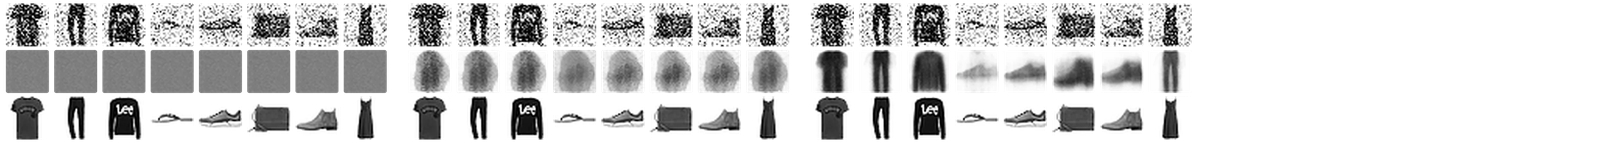

**Hỏi nhanh.** Một đội viết vòng train denoising, nhưng dòng loss lại là `loss = (model(corrupted) - corrupted).square().mean()`. Mục tiêu học đã thành gì?

- A. Vẫn dựng lại bản sạch, chỉ là hội tụ chậm hơn
- B. Dự đoán riêng phần nhiễu để trừ đi sau
- C. Dựng lại chính input có nhiễu, như autoencoder thường
- D. Không học gì, vì loss bằng 0 ngay từ đầu

<details><summary>Đáp án</summary>

C. Dựng lại chính input có nhiễu, như autoencoder thường

Target là chính input có nhiễu, nên đây chỉ là autoencoder thông thường trên dữ liệu nhiễu: model được thưởng khi dựng lại được cả nhiễu. Nút thắt hẹp có thể tình cờ bỏ bớt một phần nhiễu, nhưng loss không còn đòi điều đó nữa, và latent rộng thì sẽ chép nguyên nhiễu. Muốn dự đoán phần nhiễu thì target phải là `corrupted - clean`. Loss chỉ bằng 0 khi model đã thành phép đồng nhất.

</details>

**Hỏi nhanh.** Tín hiệu sạch nằm trên một mặt phẳng 2 chiều trong không gian 10 chiều. Nhiễu Gaussian đều theo mọi hướng cho MSE 0.05 so với bản sạch. Chiếu đúng lên mặt phẳng ấy thì MSE còn khoảng bao nhiêu?

- A. 0.005
- B. 0.01
- C. 0.025
- D. 0.04

<details><summary>Đáp án</summary>

B. 0.01

Nhiễu đều theo mọi hướng thì chia đều năng lượng cho 10 chiều. Phép chiếu giữ lại 2 chiều, tức giữ $2/10$, nên còn $0.05\cdot 0.2 = 0.01$. 0.04 là nhầm phép chiếu bỏ 2 chiều thay vì giữ 2 chiều. 0.005 là chỉ giữ một chiều. 0.025 là chia đôi theo cảm tính. Đây là trường hợp lý tưởng; một denoiser thật còn phải cộng thêm sai số khi học ra mặt phẳng.

</details>

## Từ autoencoder tới VAE

Code của autoencoder thường không có hình dạng gì đặc biệt: hai điểm gần nhau trong không gian code chưa chắc giải mã ra hai mẫu giống nhau, và một điểm lấy bừa thường giải mã ra thứ vô nghĩa. Variational autoencoder (VAE) sửa điều này để sinh được mẫu mới. Encoder không trả một điểm mà trả trung bình $\boldsymbol\mu$ và độ lệch chuẩn $\boldsymbol\sigma$ của một phân phối chuẩn; ta lấy $\mathbf z = \boldsymbol\mu + \boldsymbol\sigma \odot \boldsymbol\varepsilon$ với $\boldsymbol\varepsilon \sim N(0, I)$ rồi giải mã. Viết như vậy (reparameterization) để phần ngẫu nhiên nằm ở $\boldsymbol\varepsilon$, còn gradient vẫn đi qua $\boldsymbol\mu$ và $\boldsymbol\sigma$.

Loss gồm lỗi tái tạo cộng một khoản KL kéo phân phối code của từng mẫu về $N(0, I)$. KL divergence $\mathrm{KL}(P \Vert Q) = \sum_x P(x)\log\frac{P(x)}{Q(x)}$ đo phân phối $P$ lệch khỏi $Q$ bao nhiêu; nó bằng 0 khi hai phân phối trùng nhau và không đối xứng: $P = (0.5, 0.5)$, $Q = (0.9, 0.1)$ cho $\mathrm{KL}(P \Vert Q) \approx 0.51$ nhưng $\mathrm{KL}(Q \Vert P) \approx 0.37$. Với hai phân phối chuẩn một chiều, $\mathrm{KL}\big(N(\mu_1, \sigma_1^2) \Vert N(\mu_2, \sigma_2^2)\big) = \ln\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac12$, nên $N(1, 1)$ so với $N(0, 1)$ cho $0.5$. Nhờ khoản KL, code của các mẫu xếp chặt quanh gốc và phủ lên nhau, nên lấy $\mathbf z \sim N(0, I)$ rồi giải mã là sinh được mẫu mới.

Hai khoản kéo nhau. Bỏ KL thì VAE thành autoencoder thường: code rời rạc, lấy mẫu từ $N(0, I)$ ra rác. Nhân KL với $\beta > 1$ (β-VAE) thì code gọn hơn và các chiều hay tách thành những yếu tố riêng, đổi lại ảnh tái tạo mờ hơn. Decoder quá mạnh, như mô hình tự hồi quy cho văn bản, có thể bỏ qua $\mathbf z$ và đẩy KL về 0; cách chữa thường gặp là tăng dần hệ số KL từ 0 (KL annealing). VQ-VAE thay code liên tục bằng vector gần nhất trong một bảng mã; bước chọn không khả vi nên gradient được chép thẳng từ đầu vào decoder sang đầu ra encoder, đúng mẹo straight-through ở bài 3.1. Chiều của KL cũng là một lựa chọn: cực tiểu $\mathrm{KL}(p \Vert q)$ theo $q$ buộc $q$ phủ mọi chỗ $p$ có xác suất, còn $\mathrm{KL}(q \Vert p)$ cho phép $q$ bỏ bớt và dồn vào một đỉnh của $p$.

## Bẫy cài đặt

Fit scaler hoặc threshold trên test làm mất tính độc lập của phép chấm. Train lẫn nhiều anomaly làm model học tái tạo chính các anomaly ấy. Model quá mạnh tái tạo tốt cả mẫu lạ; model quá yếu báo nhầm cả mẫu bình thường. Score phụ thuộc thang feature, nên khi một mẫu bị báo, cần xem lỗi từng feature thay vì chỉ một con số.

Mẫu bị flag cũng chưa chắc là lỗi thật: score cao chỉ nói mẫu khác dữ liệu train. Kiểm FP/FN theo từng nhóm thiết bị, kiểm lệch phân phối và dữ liệu thiếu trước khi kết luận.

**Hỏi nhanh.** Log train của một nhà máy lẫn khoảng 20% mẫu lỗi, tất cả cùng một kiểu, và chưa ai gắn nhãn. Train autoencoder trên toàn bộ log rồi chấm bằng lỗi tái tạo. Kiểu lỗi ấy dễ bị làm sao?

- A. Bị báo nhiều hơn, vì model đã thấy kiểu lỗi đó
- B. Không đổi gì, vì autoencoder không dùng nhãn
- C. Không đổi gì, vì 20% vẫn là thiểu số trong train
- D. Bị bỏ sót, vì model đã học cách tái tạo kiểu lỗi đó

<details><summary>Đáp án</summary>

D. Bị bỏ sót, vì model đã học cách tái tạo kiểu lỗi đó

Autoencoder học tái tạo những gì hay gặp trong train. 20% mẫu cùng một kiểu đủ tạo thành một cấu trúc được giữ lại, nên lỗi tái tạo của chúng thấp. Không dùng nhãn không có nghĩa là không học gì từ mẫu lỗi, và “đã thấy” làm score giảm chứ không tăng. Cách sửa thường dùng là train một vòng đầu, bỏ những mẫu có score cao, rồi train lại trên phần còn lại.

</details>

## Khi đi thi

- **Đọc metric trước khi chọn ngưỡng.** Đề chấm AUC hay average precision thì nộp score liên tục, không cần ngưỡng; đề chấm F1 hay đòi nhãn 0/1 thì ngưỡng là hyperparameter chọn trên validation.
- **Học mọi thứ từ train và validation.** Scaler, model và ngưỡng đều fit trên dữ liệu bình thường của train/validation; test chỉ để dự đoán. Nếu train có thể lẫn mẫu lạ, lọc bớt mẫu có score cao rồi train lại.
- **Chạy PCA trước.** Vài dòng, vài giây CPU, và là cận dưới của mọi autoencoder tuyến tính; mạng sâu hơn chỉ đáng giữ khi thắng PCA trên metric của đề trong ngân sách thời gian.
- **Kiểm submission.** Một score mỗi mẫu (shape `(n,)`, không phải `(n, d)`), đúng thứ tự id, đúng chiều đề quy ước: score lớn là bất thường hay ngược lại.
- **Xem lỗi từng feature trước khi kết luận.** Một cột lệch thang hoặc thiếu giá trị có thể chiếm gần hết score.

## Tóm tắt

Autoencoder học nén rồi dựng lại; loss quyết định thông tin nào được giữ. Autoencoder tuyến tính tối ưu học đúng phép chiếu PCA, nên PCA vừa là baseline vừa là cận dưới MSE. Reconstruction error là một score: cần ngưỡng chọn trên validation và đánh giá bằng FP/FN, không phải kết luận nhân quả. Denoising dùng input nhiễu và target sạch, và chỉ được kiểm trên đúng loại nhiễu đã đo. Nén, khử nhiễu và phát hiện bất thường dùng cùng kiến trúc nhưng ba cách đánh giá khác nhau; mọi bước scale, chọn model/ngưỡng và chấm test phải tách rõ.

## Kiểm tra cuối bài

**Câu 1.** Một autoencoder tuyến tính một chiều dùng encoder $z = \hat{\mathbf e}^\top\mathbf x$, với $\hat{\mathbf e}$ là vector đơn vị cùng hướng với $(1, -2, 3)$. Với $\mathbf x = (-1, -4, 6)$, latent $z$ bằng bao nhiêu?

- A. $25/\sqrt{14}$
- B. $25/14$
- C. $9/\sqrt{14}$
- D. $25$

<details><summary>Đáp án</summary>

A. $25/\sqrt{14}$

$\hat{\mathbf e} = (1, -2, 3)/\sqrt{14}$, và $(1, -2, 3)\cdot(-1, -4, 6) = -1 + 8 + 18 = 25$, nên $z = 25/\sqrt{14}$. Ra 25 là quên chuẩn hóa hướng. $25/14$ là hệ số của $(1, -2, 3)$ chưa chuẩn hóa trong bản tái tạo, không phải tọa độ trên vector đơn vị. $9/\sqrt{14}$ là do sai dấu ở tích $(-2)(-4)$.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 2.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=5)

</details>

**Câu 2.** Tiếp Câu 1, decoder dựng $\hat{\mathbf x} = z\,\hat{\mathbf e}$. Vector sai số tái tạo $\mathbf r = \mathbf x - \hat{\mathbf x}$ là gì?

- A. $\frac{1}{14}(-39, -6, 9)$
- B. $\frac{1}{14}(39, 6, -9)$
- C. $\frac{1}{14}(25, -50, 75)$
- D. $\frac{1}{14}(-23, -38, 57)$

<details><summary>Đáp án</summary>

A. $\frac{1}{14}(-39, -6, 9)$

$\hat{\mathbf x} = \frac{25}{\sqrt{14}}\cdot\frac{(1, -2, 3)}{\sqrt{14}} = \frac{1}{14}(25, -50, 75)$, nên $\mathbf r = \frac{1}{14}(-14 - 25,\,-56 + 50,\,84 - 75) = \frac{1}{14}(-39, -6, 9)$. Kiểm nhanh: $\mathbf r\cdot(1, -2, 3) = -39 + 12 + 27 = 0$, phần dư vuông góc với hướng chính, đúng như một phép chiếu. $\frac{1}{14}(25, -50, 75)$ là chính bản tái tạo. $\frac{1}{14}(39, 6, -9)$ là $\hat{\mathbf x} - \mathbf x$, ngược dấu. $\frac{1}{14}(-23, -38, 57)$ là do tích vô hướng bị sai dấu, ra 9.
Đề thi: [USA-NA-AIO 2026 · Vòng 1 · Part 2.3](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=5)

</details>

**Câu 3.** Một đội muốn nén mạnh hơn. Trên cùng một tập train đã trừ trung bình, họ đổi PCA từ $k$ thành phần, với MSE tái tạo $M_k$, xuống $k - 1$ thành phần đầu, với MSE $M_{k-1}$. Câu nào luôn đúng?

- A. $M_{k-1} \ge M_k$
- B. $M_{k-1} \le M_k$
- C. $M_{k-1} = M_k$ nếu dữ liệu đã chuẩn hóa
- D. Không so được nếu không biết nhãn

<details><summary>Đáp án</summary>

A. $M_{k-1} \ge M_k$

Mỗi thành phần chính gánh một phần phương sai không âm, bằng trị riêng $\lambda_k \ge 0$. Bỏ nó đi thì phần ấy chuyển sang lỗi tái tạo: $M_{k-1} - M_k = \lambda_k/d \ge 0$, và chỉ bằng 0 khi $\lambda_k = 0$. Chuẩn hóa không làm trị riêng bằng 0, và PCA không dùng nhãn. Với autoencoder học bằng SGD, “luôn” chỉ đúng khi cả hai model đã tới nghiệm tối ưu; hai lần train dở dang có thể cho thứ tự ngược lại.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q9.2(i)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=48)

</details>

**Câu 4.** Trong một bộ dữ liệu, phương sai lớn nhất nằm theo hướng $\mathbf u$, còn nhãn chỉ phụ thuộc vào hướng $\mathbf v \perp \mathbf u$, nơi phương sai rất nhỏ. Lấy latent của một autoencoder tuyến tính một chiều đã train tốt làm feature duy nhất cho classifier. Kết quả dễ thấy nhất là gì?

- A. Classifier tốt, vì latent giữ gần hết phương sai
- B. Gần như đoán mò, vì latent bám theo $\mathbf u$
- C. Classifier tốt, vì autoencoder tự giữ hướng có ích cho nhãn
- D. Gần như đoán mò, vì latent một chiều thì luôn vô dụng

<details><summary>Đáp án</summary>

B. Gần như đoán mò, vì latent bám theo $\mathbf u$

Autoencoder tuyến tính tối ưu học ra phép chiếu PCA: giữ hướng phương sai lớn $\mathbf u$, bỏ $\mathbf v$, và thông tin về nhãn mất đúng ở chỗ ấy. Mục tiêu reconstruction không nhìn thấy nhãn, nên không có lý do gì để giữ $\mathbf v$. Giữ nhiều phương sai không có nghĩa là giữ thông tin cho nhãn. Latent một chiều không phải lúc nào cũng vô dụng: nếu nhãn phụ thuộc vào $\mathbf u$ thì nó là đủ.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q9.2(iii)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=48)

</details>

**Câu 5.** Trên dữ liệu 20 cột đã trừ trung bình, một đội giữ đủ cả 20 thành phần PCA, rồi lấy lỗi tái tạo của từng mẫu làm score bất thường. Kết quả là gì?

- A. Báo lỗi, vì PCA phải giữ ít chiều hơn input
- B. Tách tốt nhất, vì giữ đủ 100% phương sai
- C. Mẫu nào cũng được dựng đúng, nên score đều bằng 0
- D. Chỉ mẫu bất thường còn có lỗi tái tạo khác 0

<details><summary>Đáp án</summary>

C. Mẫu nào cũng được dựng đúng, nên score đều bằng 0

PCA không bắt buộc phải giữ ít chiều hơn input: giữ tới đúng 20 thành phần vẫn được, và `PCA(n_components=20)` chạy bình thường. Khi đó 20 vector trực chuẩn tạo thành một cơ sở của cả không gian, $VV^\top = I$, nên $\hat{\mathbf x} = \mathbf x$ với mọi mẫu. Mẫu bất thường cũng là một vector trong không gian ấy, nên cũng được dựng đúng, score chỉ còn sai số làm tròn. Giữ đủ phương sai là nén không mất mát, nhưng xóa luôn tín hiệu cần đo: lỗi tái tạo chỉ phân biệt được các mẫu khi có nút thắt. Autoencoder có latent rộng bằng hoặc hơn input cũng gặp đúng chuyện này khi học được phép đồng nhất. Cách sửa là thu hẹp latent, hoặc dùng denoising hay regularization để model không chép thẳng được.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q9.2(iv)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=49)

</details>

**Câu 6.** Hai cảm biến: nhiệt độ đo bằng °C, độ lệch chuẩn khoảng 2, và áp suất đo bằng Pa, độ lệch chuẩn khoảng 500. Train autoencoder trên số liệu thô với MSE. Lỗi tái tạo sẽ chủ yếu phản ánh điều gì?

- A. Cột áp suất, vì sai số đo theo Pa lớn hơn nhiều
- B. Cột nhiệt độ, vì nó biến động tương đối nhiều hơn
- C. Cả hai như nhau, vì MSE lấy trung bình theo cột
- D. Không cột nào, vì autoencoder tự chuẩn hóa input

<details><summary>Đáp án</summary>

A. Cột áp suất, vì sai số đo theo Pa lớn hơn nhiều

MSE cộng bình phương sai số theo đơn vị gốc. Một sai lệch cỡ độ lệch chuẩn của áp suất đóng góp $500^2$, của nhiệt độ chỉ $2^2$, chênh nhau khoảng 60 000 lần. Model dồn sức tái tạo áp suất, và score bất thường gần như chỉ nhìn vào áp suất. Lấy trung bình theo cột không cân lại được thang đo, và autoencoder cũng không tự chuẩn hóa. Hãy fit `StandardScaler` trên train, hoặc đặt trọng số cho từng cột theo mục tiêu.

</details>

**Câu 7.** Ngưỡng là phân vị 95% của score trên một tập validation gồm toàn mẫu bình thường. Sau đó nhà máy thay một loạt cảm biến mới, và phân bố dữ liệu chưa được kiểm lại. Ta kết luận được gì?

- A. Ngưỡng chỉ mô tả phần đuôi score của tập validation cũ
- B. Tỉ lệ báo nhầm về sau đúng bằng 5%
- C. Recall với bất thường bằng 95%, vì chọn phân vị 95
- D. Mẫu nào vượt ngưỡng cũng chắc chắn là bất thường

<details><summary>Đáp án</summary>

A. Ngưỡng chỉ mô tả phần đuôi score của tập validation cũ

Phân vị chỉ bảo đảm khoảng 5% mẫu validation vượt ngưỡng. Cảm biến mới có thể làm dịch cả phân bố score, nên tỉ lệ báo nhầm phải đo lại trên dữ liệu mới. Recall thì cần mẫu bất thường có nhãn mới chấm được. Vượt ngưỡng chỉ nói mẫu ấy khác dữ liệu train, chưa chắc là lỗi.

</details>

**Câu 8.** Một đội viết autoencoder `Linear(10,32) → Linear(32,2) → Linear(2,32) → Linear(32,10)` nhưng quên đặt activation giữa các lớp. So với PCA 2 thành phần trên cùng tập train, MSE tái tạo tốt nhất mà mạng này đạt được là bao nhiêu?

- A. Thấp hơn PCA, nhờ có lớp ẩn rộng 32 chiều
- B. Không thấp hơn PCA, vì mạng vẫn tuyến tính và hạng không quá 2
- C. Thấp hơn PCA, nếu train đủ lâu bằng Adam
- D. Bằng 0, vì tổng số weight lớn hơn số feature

<details><summary>Đáp án</summary>

B. Không thấp hơn PCA, vì mạng vẫn tuyến tính và hạng không quá 2

Không có activation thì tích các ma trận vẫn là một ma trận, thêm bias thì thành một phép affine. Mọi thông tin phải đi qua nút thắt 2 chiều, nên hạng không quá 2. PCA 2 thành phần, tính trên dữ liệu đã trừ trung bình, đã là phép nén rồi dựng affine hạng 2 tốt nhất, nên mạng chỉ có thể bằng nó. Lớp rộng, train lâu hay nhiều weight đều không đổi được giới hạn này. Phải thêm ReLU giữa các lớp thì mạng mới học được cấu trúc cong.

</details>

**Câu 9.** Denoiser của bài được train với nhiễu Gaussian nhỏ cộng vào cả bốn cảm biến. Khi đem dùng thật, lỗi hay gặp lại là một cảm biến thỉnh thoảng bị kẹt và trả về 0. Trước khi dùng denoiser, ta nên làm gì?

- A. Dùng ngay, vì denoiser đã giảm MSE gần 4 lần
- B. Train lại với nhiễu Gaussian lớn hơn nhiều
- C. Mô phỏng lỗi kẹt về 0, rồi đo lại so với baseline
- D. Bỏ denoiser, vì autoencoder chỉ khử được nhiễu Gaussian

<details><summary>Đáp án</summary>

C. Mô phỏng lỗi kẹt về 0, rồi đo lại so với baseline

Kết quả 0.019573 xuống 0.005335 chỉ được đo trên nhiễu Gaussian đều theo mọi hướng. Lỗi kẹt là một dạng nhiễu khác hẳn: lớn và dồn vào một cột. Phải tạo đúng dạng nhiễu ấy trên validation, nếu cần thì train lại với nó, theo kiểu masking noise của denoising autoencoder, rồi so với baseline giữ nguyên input. Tăng nhiễu Gaussian không biến nó thành nhiễu kẹt. Còn autoencoder không chỉ khử được nhiễu Gaussian; nó học khử đúng loại nhiễu mà nó được train.

</details>

**Câu 10.** Ở phần ngưỡng của bài, test có 32 mẫu bình thường và 16 mẫu bất thường, output in ra `TP FP FN: 16 2 0`. Precision và recall của lớp bất thường bằng bao nhiêu?

- A. Precision 1.0, recall 0.89
- B. Precision 0.94, recall 1.0
- C. Precision 0.89, recall 0.94
- D. Precision 0.89, recall 1.0

<details><summary>Đáp án</summary>

D. Precision 0.89, recall 1.0

Precision là $16/(16 + 2) \approx 0.89$, tức cứ khoảng 9 lần báo thì có 1 lần nhầm. Recall là $16/(16 + 0) = 1$, không bỏ sót mẫu bất thường nào, nhờ nhóm bất thường nằm xa ngưỡng như trên hình lỗi tái tạo. 0.94 là tỉ lệ mẫu bình thường không bị báo, $30/32$. Đổi chỗ precision với recall là nhầm định nghĩa.

</details>

## Đọc thêm

- Goodfellow, Bengio, Courville — [Deep Learning, chương 14](https://www.deeplearningbook.org/contents/autoencoders.html): đọc nút thắt, giới hạn capacity và quan hệ với PCA.
- Vincent và cộng sự — [Stacked Denoising Autoencoders](https://www.jmlr.org/papers/v11/vincent10a.html): xem mục tiêu noisy input → clean target và học biểu diễn.
- Baldi, Hornik (1989) — *Neural Networks and Principal Component Analysis: Learning from Examples Without Local Minima*, Neural Networks 2(1). Chứng minh autoencoder tuyến tính tối ưu học đúng không gian PCA.
- [PyTorch — Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html): dùng lại training loop đã học cho reconstruction loss.

Nguồn ảnh: ảnh quần áo lấy từ bộ Fashion-MNIST của Zalando (giấy phép MIT).